# Part III: Decision Boundary and Visualization

## 1. Decision Boundary

The decision boundary is the point where the Logistic Regression model predicts a probability of 0.5.

For a single-feature Logistic Regression model:

\[
z=wx+b
\]

At the decision boundary:

\[
z=0
\]

Therefore:

\[
x=\frac{-b}{w}
\]

Using our trained model:

- Weight (w): 0.40808
- Bias (b): -1.42633
- Decision Boundary: approximately 3.495 hours

At this point, the predicted probability is 0.5.

## 2. Sigmoid Curve Visualization

The sigmoid function converts the linear output into a probability between 0 and 1.

\[
\sigma(z)=\frac{1}{1+e^{-z}}
\]

Observations:

- When z is very negative, the probability approaches 0.
- When z is 0, the probability is 0.5.
- When z is very positive, the probability approaches 1.

The sigmoid curve helps us understand how Logistic Regression produces probabilities for binary classification.

## 3. Classification Threshold

A classification threshold determines how probabilities are converted into class predictions.

Our default threshold is 0.5.

- Probability >= threshold: Class 1
- Probability < threshold: Class 0

We also implemented a custom threshold function to experiment with different threshold values.

## 4. Threshold Evaluation

We tested threshold 0.6 using our test dataset.

**Confusion Matrix:**

| Metric | Result |
|---|---:|
| True Negative | 2 |
| False Positive | 1 |
| False Negative | 0 |
| True Positive | 2 |
| Accuracy | 80% |
| Precision | 66.67% |
| Recall | 100% |

Changing the threshold affects classification decisions and can change precision and recall.

A higher threshold makes the model more conservative when predicting Class 1. This can reduce false positives but may increase false negatives.

## 5. Limitations of Our Implementation

- We trained using a very small synthetic dataset.
- We implemented only single-feature Logistic Regression.
- Our model was trained for a limited number of epochs.
- Our evaluation dataset was too small to establish real-world performance.
- We used a fixed learning rate and a default classification threshold.

## 6. Final Conclusion

In this project, I implemented Logistic Regression from scratch using NumPy without using Scikit-learn for model training.

I learned how to:

- Implement the sigmoid function.
- Calculate binary cross-entropy loss.
- Train a model using gradient descent.
- Generate probability and class predictions.
- Save and load trained model parameters.
- Evaluate predictions using a confusion matrix.
- Calculate accuracy, precision, and recall.
- Calculate and visualize the decision boundary.
- Visualize the sigmoid curve.
- Experiment with different classification thresholds.

**Status: Logistic Regression From Scratch — Completed.**

### Loading parameters

In [ ]:
import numpy as np
saved_model = np.load("model/logistic_regression_part_I_model.npz")

w_loaded = saved_model["w"].item()
b_loaded = saved_model["b"].item()

print("Weight :",w_loaded)
print("Bias :",b_loaded)

Weight : 0.40808303784853656
Bias : -1.4263280576885489


## Calculating decision boundary

In [26]:
decision_boundary = -b_loaded/w_loaded
print("Decision Boundary :",round(decision_boundary,4))

Decision Boundary : 3.4952


## Loading the existing functions

In [27]:
def sigmoid(z):
    return 1/(1+np.exp(-z))

def predict_probability(x,w,b):
    z = x*w+b
    pred = sigmoid(z)
    return pred
def predict_with_threshold(x,w,b,threshold):
    p = predict_probability(x,w,b)
    pred_class = (p >= threshold).astype(int)
    return pred_class

def log_loss(y,p):
    n = len(y)
    loss = -(1/n)*np.sum(y*np.log(p) + (1-y)*np.log(1-p))
    return loss

print("Done")

Done


## Calculating the probability at the boundary:

In [28]:
z = w_loaded * decision_boundary + b_loaded
probability = sigmoid(z)
print("Loaded Weight:", w_loaded)
print("Loaded Bias:", b_loaded)
print("Decision Boundary:", decision_boundary)
print("Z:", z)
print("Probability:", probability)

Loaded Weight: 0.40808303784853656
Loaded Bias: -1.4263280576885489
Decision Boundary: 3.4951907464919985
Z: 0.0
Probability: 0.5


## Visualising the sigmoiud function

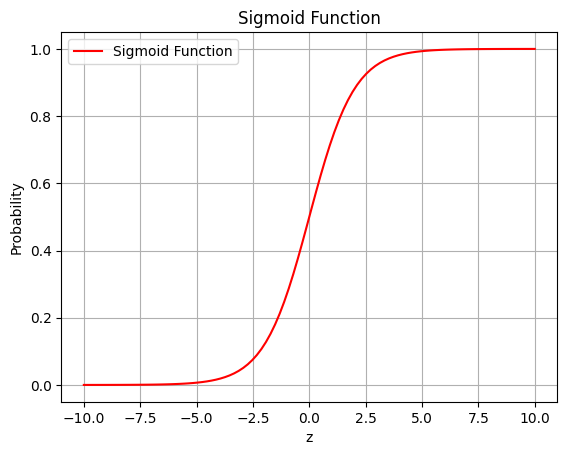

In [29]:
import matplotlib.pyplot as plt

z_values = np.linspace(-10, 10, 100)
z_pred = sigmoid(z_values)
plt.plot(z_values, z_pred, label="Sigmoid Function", color="red")
plt.xlabel("z")
plt.ylabel("Probability")
plt.title("Sigmoid Function")
plt.grid()
plt.legend()
plt.show()

## Defining the confusion matrix

In [30]:
def confusion_matrix(y_actual, y_predicted):

    tn = np.sum((y_actual == 0) & (y_predicted == 0))
    fp = np.sum((y_actual == 0) & (y_predicted == 1))
    fn = np.sum((y_actual == 1) & (y_predicted == 0))
    tp = np.sum((y_actual == 1) & (y_predicted == 1))

    accuracy = (tp + tn) / (tp + tn + fp + fn)

    recall = tp / (tp + fn) if (tp + fn) != 0 else 0

    precision = tp / (tp + fp) if (tp + fp) != 0 else 0

    cm = np.array([
        [tn, fp],
        [fn, tp]
    ])

    return cm, accuracy, recall, precision
print("Done")

Done


### Loading the same data we used in part I and part II

In [13]:
X_test = np.array([1.5, 3.5, 4.5, 5.5, 6.5])

y_test = np.array([0, 0, 0, 1, 1])

### Finding best threshold

In [23]:
def find_best_threshold(*thresholds):

    results = []

    for threshold in thresholds:

        predictions = predict_with_threshold(
            X_test, w_loaded, b_loaded, threshold
        )

        cm, accuracy, recall, precision = confusion_matrix(
            y_test, predictions
        )

        results.append({
            "threshold": threshold,
            "confusion_matrix": cm,
            "accuracy": accuracy,
            "recall": recall,
            "precision": precision,
            "predictions": predictions
        })

    return results
print("Done")

Done


### Calling the function

In [24]:
results = find_best_threshold(0.3, 0.5, 0.6, 0.7)
for result in results:
    print("Threshold:", result["threshold"])
    print("Predictions:", result["predictions"])
    print("Confusion Matrix:\n", result["confusion_matrix"])
    print("Accuracy:", result["accuracy"])
    print("Recall:", result["recall"])
    print("Precision:", result["precision"])
    print("-------------------------")

Threshold: 0.3
Predictions: [1 1 1 1 1]
Confusion Matrix:
 [[0 3]
 [0 2]]
Accuracy: 0.4
Recall: 1.0
Precision: 0.4
-------------------------
Threshold: 0.5
Predictions: [0 1 1 1 1]
Confusion Matrix:
 [[1 2]
 [0 2]]
Accuracy: 0.6
Recall: 1.0
Precision: 0.5
-------------------------
Threshold: 0.6
Predictions: [0 0 1 1 1]
Confusion Matrix:
 [[2 1]
 [0 2]]
Accuracy: 0.8
Recall: 1.0
Precision: 0.6666666666666666
-------------------------
Threshold: 0.7
Predictions: [0 0 0 0 1]
Confusion Matrix:
 [[3 0]
 [1 1]]
Accuracy: 0.8
Recall: 0.5
Precision: 1.0
-------------------------


# End of Logistic Regression From Scratch

Logistic Regression implementation is now complete.

I built the model from scratch using NumPy, trained it using Gradient Descent, evaluated its performance, visualized the sigmoid curve and decision boundary, and experimented with classification thresholds.

This project strengthened my understanding of the internal working of Logistic Regression and the complete binary classification workflow.

**Next:** Real-world CSV projects using Linear Regression and Logistic Regression.

**Status: COMPLETED**

